In [1]:
# ==============================================================================
# Cell 1 — Step 1: Data Load & Global Configuration 
# ==============================================================================
import warnings
import time
import joblib
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, HuberRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    median_absolute_error,
    r2_score
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

@dataclass(frozen=True)
class PipelineConfig:
    DATA_PATH: str = "/home/hima/Documents/work/sair_projects/classical_ml/victoria_electricity_data_forecasting_dataset.csv"  # put your data path here 
    TARGET_COL: str = "demand"
    DATE_COL: str = "date"
    VAL_SIZE: float = 0.15
    TEST_SIZE: float = 0.15
    RANDOM_STATE: int = 42
    N_JOBS: int = -1
    MODEL_SAVE_PATH: str = "victoria_demand_pipeline.pkl"

config = PipelineConfig()

# Load raw dataset (strictly read-only, preserving all 2,106 rows x 14 columns)
df_raw = pd.read_csv(config.DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()

print("=" * 80)
print("✅ Cell 1 (Step 1) Complete: Raw Dataset Loaded & Config Initialized")
print("=" * 80)
print(f"• File Path     : {config.DATA_PATH}")
print(f"• Dataset Shape : {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"• Target Column : '{config.TARGET_COL}'")
display(df_raw.head(5))

✅ Cell 1 (Step 1) Complete: Raw Dataset Loaded & Config Initialized
• File Path     : /home/hima/Documents/work/sair_projects/classical_ml/victoria_electricity_data_forecasting_dataset.csv
• Dataset Shape : 2,106 rows x 14 columns
• Target Column : 'demand'


,date,demand,RRP,demand_pos_RRP,RRP_positive,demand_neg_RRP,RRP_negative,frac_at_neg_RRP,min_temperature,max_temperature,solar_exposure,rainfall,school_day,holiday
0,2015-01-01,99635.030,25.633696,97319.240,26.415953,2315.790,-7.240000,0.020833,13.3,26.9,23.6,0.0,N,Y
1,2015-01-02,129606.010,33.138988,121082.015,38.837661,8523.995,-47.809777,0.062500,15.4,38.8,26.8,0.0,N,N
2,2015-01-03,142300.540,34.564855,142300.540,34.564855,0.000,0.000000,0.000000,20.0,38.2,26.5,0.0,N,N
3,2015-01-04,104330.715,25.005560,104330.715,25.005560,0.000,0.000000,0.000000,16.3,21.4,25.2,4.2,N,N
4,2015-01-05,118132.200,26.724176,118132.200,26.724176,0.000,0.000000,0.000000,15.0,22.0,30.7,0.0,N,N


In [2]:
# ==============================================================================
# Cell 2 — Step 2.1: Check Missing Values, Duplicates & Date Continuity 
# ==============================================================================
missing_counts = df_raw.isna().sum()
missing_pct = (missing_counts / len(df_raw)) * 100

missing_report = pd.DataFrame({
    "Missing_Count": missing_counts,
    "Missing_Percent (%)": missing_pct.round(4),
    "Dtype": df_raw.dtypes
})

# Check full-row duplicates and date-level duplicates
full_duplicates = df_raw.duplicated().sum()
date_duplicates = df_raw[config.DATE_COL].duplicated().sum()

# Check chronological continuity (are any calendar days skipped?)
dt_series = pd.to_datetime(df_raw[config.DATE_COL]).sort_values()
expected_days = (dt_series.max() - dt_series.min()).days + 1
missing_calendar_days = expected_days - len(dt_series)

print("=" * 80)
print("✅ Cell 2 (Step 2.1) Complete: Missing Values & Continuity Audit (Read-Only)")
print("=" * 80)
print(f"• Total Rows Audited       : {len(df_raw):,} rows")
print(f"• Full Duplicate Rows      : {full_duplicates}")
print(f"• Duplicate Dates          : {date_duplicates}")
print(f"• Date Range               : {dt_series.min().date()} to {dt_series.max().date()} ({expected_days:,} expected days)")
print(f"• Skipped Calendar Days    : {missing_calendar_days}")

print("\n📋 Columns with Missing Values:")
display(missing_report[missing_report["Missing_Count"] > 0])

print("\n🔍 Exact Rows Containing Missing Values:")
display(df_raw[df_raw.isna().any(axis=1)][["date", "demand", "RRP", "min_temperature", "max_temperature", "solar_exposure", "rainfall"]])

✅ Cell 2 (Step 2.1) Complete: Missing Values & Continuity Audit (Read-Only)
• Total Rows Audited       : 2,106 rows
• Full Duplicate Rows      : 0
• Duplicate Dates          : 0
• Date Range               : 2015-01-01 to 2020-10-06 (2,106 expected days)
• Skipped Calendar Days    : 0

📋 Columns with Missing Values:


,Missing_Count,Missing_Percent (%),Dtype
solar_exposure,1,0.0475,float64
rainfall,3,0.1425,float64



🔍 Exact Rows Containing Missing Values:


,date,demand,RRP,min_temperature,max_temperature,solar_exposure,rainfall
161,2015-06-11,143465.445,37.481829,5.7,14.0,8.3,NaN
1060,2017-11-26,108717.875,83.114514,19.4,28.3,NaN,3.4
1377,2018-10-09,116449.310,99.000749,16.1,17.9,7.2,NaN
1378,2018-10-10,109551.080,73.539698,10.1,16.5,20.0,NaN


In [3]:
# ==============================================================================
# Cell 3 — Step 2.2: Checking Data Types, Cardinality & Statistical Summary
# ==============================================================================
# 1. Data Type & Cardinality Report
dtype_report = pd.DataFrame({
    "Data_Type": df_raw.dtypes,
    "Non_Null_Count": df_raw.notnull().sum(),
    "Null_Count": df_raw.isna().sum(),
    "Unique_Values": df_raw.nunique(),
    "Sample_Row_0": df_raw.iloc[0].values
})

print("=" * 85)
print("✅ Cell 3 (Step 2.2) Complete: Data Types & Statistical Summary Audit (Read-Only)")
print("=" * 85)
display(dtype_report)

# 2. Inspect Categorical ('object') Columns Unique Levels
obj_cols = [c for c in df_raw.select_dtypes(include=["object"]).columns if c != config.DATE_COL]
print("\n🔤 Categorical Columns Unique Values & Frequencies:")
for col in obj_cols:
    val_counts = df_raw[col].value_counts(dropna=False).to_dict()
    print(f"• {col:<12} -> {val_counts}")

# 3. Comprehensive Numerical Summary (Including Skewness, Kurtosis & IQR)
num_cols_raw = df_raw.select_dtypes(include=[np.number]).columns
desc_df = df_raw[num_cols_raw].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T
desc_df["IQR"] = desc_df["75%"] - desc_df["25%"]
desc_df["Skewness"] = df_raw[num_cols_raw].skew()
desc_df["Kurtosis"] = df_raw[num_cols_raw].kurtosis()

cols_order = ["count", "mean", "std", "min", "25%", "50%", "75%", "99%", "max", "IQR", "Skewness", "Kurtosis"]
print("\n📊 Extended Numerical Distribution Summary (Target = 'demand' vs. 'RRP'):")
display(desc_df[cols_order].round(2))

✅ Cell 3 (Step 2.2) Complete: Data Types & Statistical Summary Audit (Read-Only)


,Data_Type,Non_Null_Count,Null_Count,Unique_Values,Sample_Row_0
date,object,2106,0,2106,2015-01-01
demand,float64,2106,0,2106,99635.03
RRP,float64,2106,0,2106,25.633696
demand_pos_RRP,float64,2106,0,2106,97319.24
RRP_positive,float64,2106,0,2106,26.415953
demand_neg_RRP,float64,2106,0,192,2315.79
RRP_negative,float64,2106,0,179,-7.24
frac_at_neg_RRP,float64,2106,0,21,0.020833
min_temperature,float64,2106,0,211,13.3
max_temperature,float64,2106,0,283,26.9



🔤 Categorical Columns Unique Values & Frequencies:
• school_day   -> {'Y': 1453, 'N': 653}
• holiday      -> {'N': 2029, 'Y': 77}

📊 Extended Numerical Distribution Summary (Target = 'demand' vs. 'RRP'):


,count,mean,std,min,25%,50%,75%,99%,max,IQR,Skewness,Kurtosis
demand,2106.0,120035.48,13747.99,85094.37,109963.65,119585.91,130436.01,152492.40,170653.84,20472.36,0.19,-0.33
RRP,2106.0,76.08,130.25,-6.08,38.71,66.60,95.08,188.19,4549.65,56.37,24.78,761.38
demand_pos_RRP,2106.0,119252.31,14818.63,41988.24,109246.25,119148.08,130119.48,152334.53,170653.84,20873.23,-0.19,0.67
RRP_positive,2106.0,76.55,130.11,13.57,39.12,66.87,95.13,188.19,4549.65,56.01,24.85,764.14
demand_neg_RRP,2106.0,783.17,3578.92,0.00,0.00,0.00,0.00,19030.45,57597.60,0.00,7.20,69.66
RRP_negative,2106.0,-2.69,19.49,-342.22,0.00,0.00,0.00,0.00,0.00,0.00,-12.29,175.77
frac_at_neg_RRP,2106.0,0.01,0.04,0.00,0.00,0.00,0.00,0.21,0.62,0.00,7.42,73.35
min_temperature,2106.0,11.58,4.31,0.60,8.50,11.30,14.60,22.09,28.00,6.10,0.30,-0.18
max_temperature,2106.0,20.41,6.29,9.00,15.52,19.10,23.90,38.10,43.50,8.37,0.92,0.45
solar_exposure,2105.0,14.74,7.95,0.70,8.20,12.70,20.70,31.90,33.30,12.50,0.57,-0.80


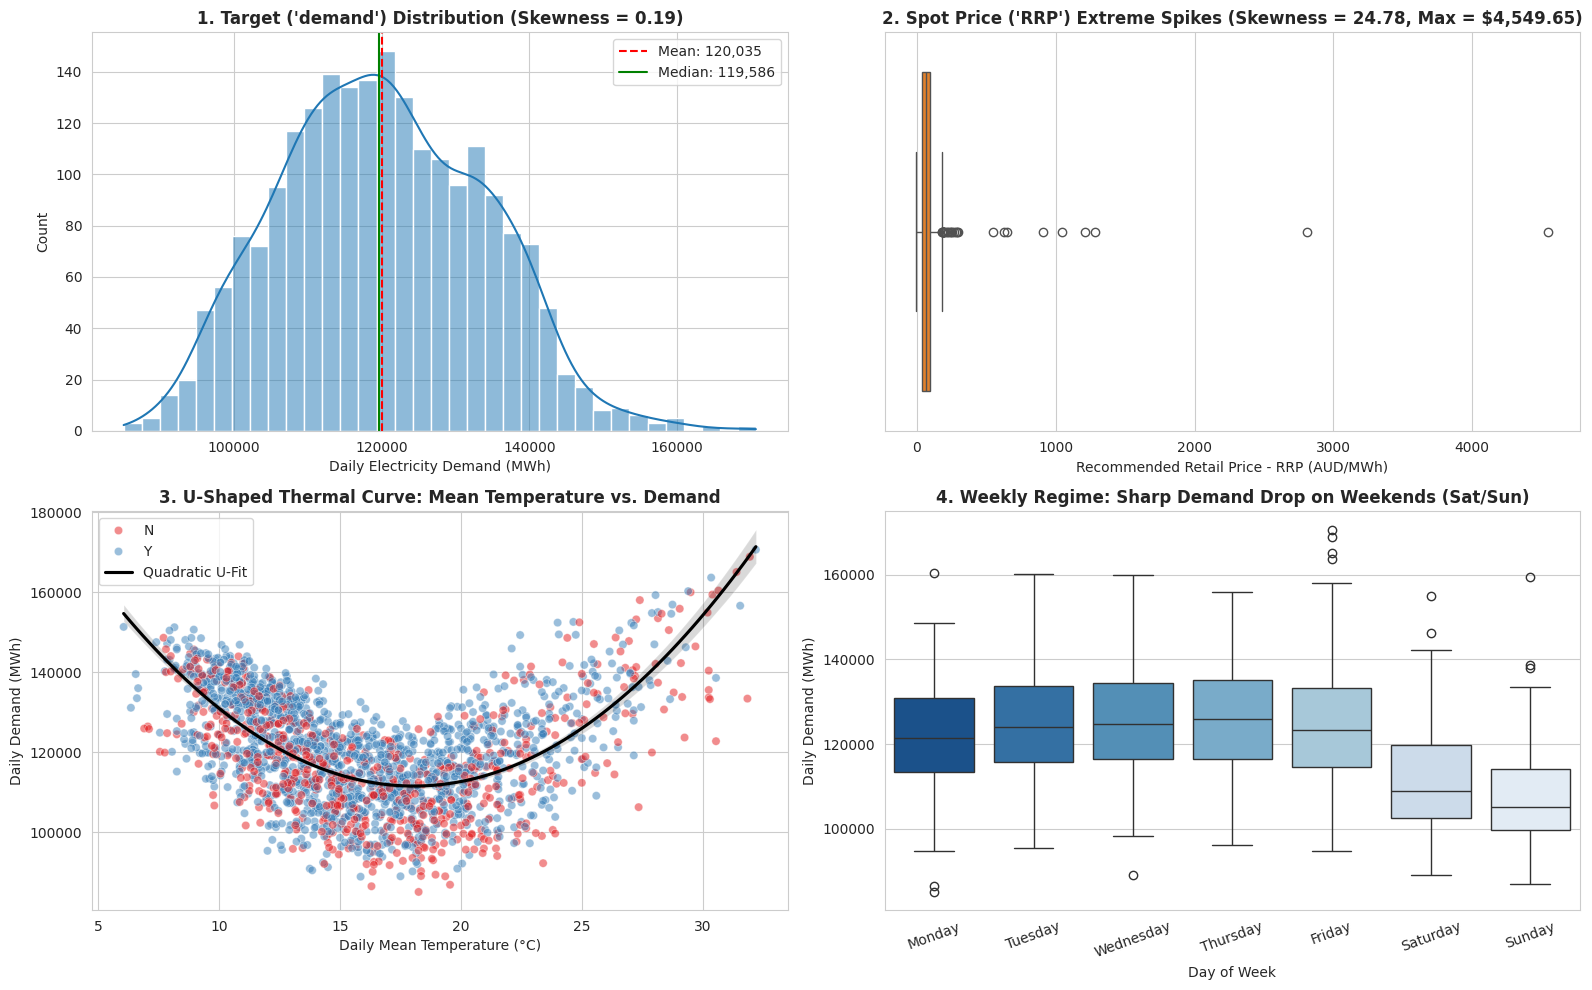

✅ Cell 4 (Step 2.3) Complete: 4 Key Domain Distributions Visualized
• Insight 1: 'demand' is symmetric (Skew = 0.19), whereas 'RRP' has extreme heatwave outliers (Skew = 24.78).
• Insight 2: Demand follows a clear U-shaped curve with temperature (Heating < 18°C, Cooling > 22°C).
• Insight 3: Demand drops sharply on Saturdays and Sundays, justifying 'is_weekend' & interaction features.


In [4]:
# ==============================================================================
# Cell 4 — Step 2.3: Distribution Visualizations (Read-Only Diagnostic Plots)
# ==============================================================================
# Create a temporary read-only copy for visualization purposes only
df_viz = df_raw.copy()
df_viz["date"] = pd.to_datetime(df_viz["date"])
df_viz["day_name"] = df_viz["date"].dt.day_name()
df_viz["temp_mean"] = (df_viz["max_temperature"] + df_viz["min_temperature"]) / 2.0

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Plot 1: Target ('demand') Near-Normal Distribution (Skew = 0.19)
sns.histplot(df_viz["demand"], kde=True, bins=35, color="#1f77b4", ax=axes[0, 0])
axes[0, 0].axvline(df_viz["demand"].mean(), color="red", linestyle="--", label=f"Mean: {df_viz['demand'].mean():,.0f}")
axes[0, 0].axvline(df_viz["demand"].median(), color="green", linestyle="-", label=f"Median: {df_viz['demand'].median():,.0f}")
axes[0, 0].set_title(f"1. Target ('demand') Distribution (Skewness = {df_viz['demand'].skew():.2f})", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Daily Electricity Demand (MWh)")
axes[0, 0].legend()

# Plot 2: Spot Price ('RRP') Extreme Skewness & Outliers (Skew = 24.78)
sns.boxplot(x=df_viz["RRP"], color="#ff7f0e", ax=axes[0, 1])
axes[0, 1].set_title(f"2. Spot Price ('RRP') Extreme Spikes (Skewness = {df_viz['RRP'].skew():.2f}, Max = $4,549.65)", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Recommended Retail Price - RRP (AUD/MWh)")

# Plot 3: U-Shaped Non-Linear Thermal Curve (Mean Temp vs. Demand)
sns.scatterplot(
    data=df_viz, x="temp_mean", y="demand",
    hue="school_day", alpha=0.5, palette="Set1", ax=axes[1, 0]
)
sns.regplot(
    data=df_viz, x="temp_mean", y="demand",
    scatter=False, order=2, color="black", ax=axes[1, 0], label="Quadratic U-Fit"
)
axes[1, 0].set_title("3. U-Shaped Thermal Curve: Mean Temperature vs. Demand", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Daily Mean Temperature (°C)")
axes[1, 0].set_ylabel("Daily Demand (MWh)")
axes[1, 0].legend()

# Plot 4: Weekly Seasonality & Weekend Drop (Day of Week vs. Demand)
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sns.boxplot(
    data=df_viz, x="day_name", y="demand",
    order=day_order, palette="Blues_r", ax=axes[1, 1]
)
axes[1, 1].set_title("4. Weekly Regime: Sharp Demand Drop on Weekends (Sat/Sun)", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Day of Week")
axes[1, 1].set_ylabel("Daily Demand (MWh)")
axes[1, 1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

print("=" * 85)
print("✅ Cell 4 (Step 2.3) Complete: 4 Key Domain Distributions Visualized")
print("=" * 85)
print("• Insight 1: 'demand' is symmetric (Skew = 0.19), whereas 'RRP' has extreme heatwave outliers (Skew = 24.78).")
print("• Insight 2: Demand follows a clear U-shaped curve with temperature (Heating < 18°C, Cooling > 22°C).")
print("• Insight 3: Demand drops sharply on Saturdays and Sundays, justifying 'is_weekend' & interaction features.")

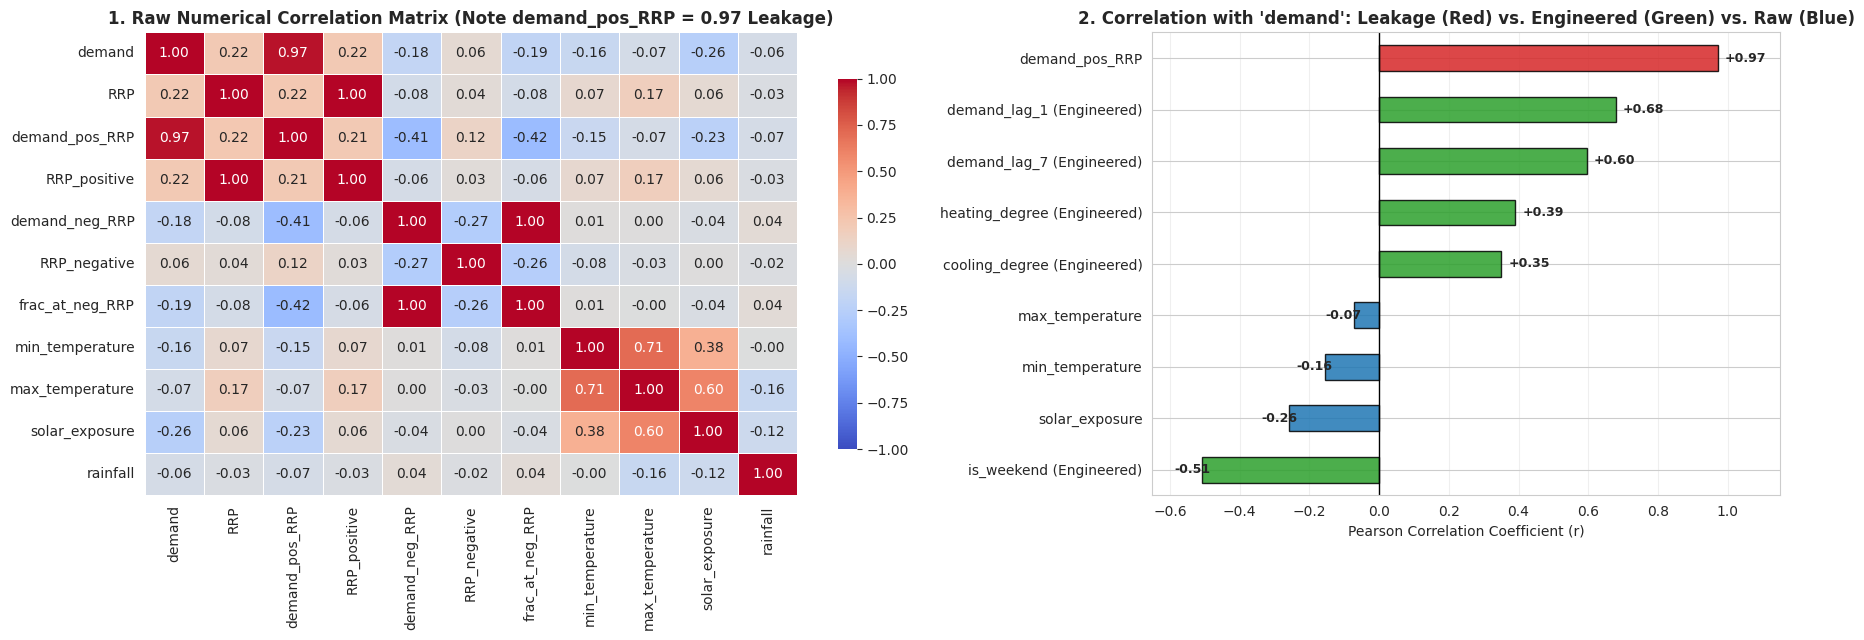

✅ Cell 5 (Step 2.4) Complete: Correlation & Leakage Audit Summary
• Target Leakage Proof : 'demand_pos_RRP' correlates at r = 0.9714 with 'demand' (must drop same-day values!).
• U-Curve Proof        : Raw 'max_temperature' has r = -0.0732 because winter heating & summer cooling cancel out linearly.
• Feature Engineering  : Decomposing temp into 'heating_degree' (r = +0.39) and adding 'demand_lag_1' (r = +0.68) exposes strong predictive signals.


In [5]:
# ==============================================================================
# Cell 5 — Step 2.4: Correlation Analysis & Leakage / Non-Linearity Audit (Read-Only)
# ==============================================================================
# 1. Compute Pearson Correlation Matrix on Raw Numerical Columns (Read-Only)
num_raw_cols = df_raw.select_dtypes(include=[np.number]).columns
corr_matrix = df_raw[num_raw_cols].corr()

# 2. Create a temporary read-only dataframe to compare Raw vs. Engineered Correlations with 'demand'
df_corr_check = df_raw.copy()
df_corr_check["date"] = pd.to_datetime(df_corr_check["date"])
df_corr_check = df_corr_check.sort_values("date").reset_index(drop=True)

temp_mean = (df_corr_check["max_temperature"] + df_corr_check["min_temperature"]) / 2.0
df_corr_check["heating_degree (Engineered)"] = np.maximum(0.0, 18.0 - temp_mean)
df_corr_check["cooling_degree (Engineered)"] = np.maximum(0.0, temp_mean - 22.0)
df_corr_check["demand_lag_1 (Engineered)"] = df_corr_check["demand"].shift(1)
df_corr_check["demand_lag_7 (Engineered)"] = df_corr_check["demand"].shift(7)
df_corr_check["is_weekend (Engineered)"] = (df_corr_check["date"].dt.dayofweek >= 5).astype(int)

compare_cols = [
    "demand_pos_RRP",              # Same-day leakage!
    "demand_lag_1 (Engineered)",   # Legitimate past lag
    "demand_lag_7 (Engineered)",   # Legitimate weekly lag
    "heating_degree (Engineered)", # Winter branch of U-curve
    "cooling_degree (Engineered)", # Summer branch of U-curve
    "max_temperature",             # Raw linear temp (misleadingly negative due to U-curve)
    "min_temperature",             # Raw linear min temp
    "solar_exposure",              # Raw solar
    "is_weekend (Engineered)"      # Weekend regime drop
]
target_corrs = df_corr_check[compare_cols].apply(lambda x: df_corr_check["demand"].corr(x)).sort_values()

# 3. Plot Raw Heatmap & Target Correlation Comparison Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})

# Left Plot: Raw Numerical Correlation Heatmap
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
    vmin=-1, vmax=1, linewidths=0.5, ax=axes[0], cbar_kws={"shrink": 0.8}
)
axes[0].set_title("1. Raw Numerical Correlation Matrix (Note demand_pos_RRP = 0.97 Leakage)", fontsize=12, fontweight="bold")

# Right Plot: Linear Correlation with Target ('demand') - Raw vs. Domain Engineered
colors = ["#d62728" if "demand_pos_RRP" in idx else ("#2ca02c" if "Engineered" in idx else "#1f77b4") for idx in target_corrs.index]
target_corrs.plot(kind="barh", color=colors, ax=axes[1], edgecolor="black", alpha=0.85)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("2. Correlation with 'demand': Leakage (Red) vs. Engineered (Green) vs. Raw (Blue)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Pearson Correlation Coefficient (r)")
axes[1].grid(True, axis="x", alpha=0.3)

for i, v in enumerate(target_corrs.values):
    axes[1].text(v + (0.02 if v >= 0 else -0.08), i, f"{v:+.2f}", va="center", fontweight="bold", fontsize=9)
axes[1].set_xlim(-0.65, 1.15)

plt.tight_layout()
plt.show()

print("=" * 85)
print("✅ Cell 5 (Step 2.4) Complete: Correlation & Leakage Audit Summary")
print("=" * 85)
print(f"• Target Leakage Proof : 'demand_pos_RRP' correlates at r = {corr_matrix.loc['demand', 'demand_pos_RRP']:.4f} with 'demand' (must drop same-day values!).")
print(f"• U-Curve Proof        : Raw 'max_temperature' has r = {corr_matrix.loc['demand', 'max_temperature']:.4f} because winter heating & summer cooling cancel out linearly.")
print(f"• Feature Engineering  : Decomposing temp into 'heating_degree' (r = {target_corrs['heating_degree (Engineered)']:+.2f}) and adding 'demand_lag_1' (r = {target_corrs['demand_lag_1 (Engineered)']:+.2f}) exposes strong predictive signals.")

In [6]:
# ==============================================================================
# Cell 6 — Step 3: Data Preprocessing & Feature Engineering (Lecture 3 Standard)
# ==============================================================================

# 3.1: Chronological Sort, Causal Weather Imputation (ffill) & Historical Lags (shift >= 1)
def build_historical_time_series(df: pd.DataFrame) -> pd.DataFrame:
    """
    1. Sorts chronologically by date.
    2. Applies causal forward-fill (ffill) on weather ('solar_exposure', 'rainfall').
    3. Extracts strictly historical lags (shift >= 1) from demand, RRP, and weather.
    4. Drops same-day (t) post-settlement leakage columns while keeping all 2,106 rows.
    """
    df_out = df.copy()
    df_out[config.DATE_COL] = pd.to_datetime(df_out[config.DATE_COL])
    df_out = df_out.sort_values(config.DATE_COL).reset_index(drop=True)

    # Causal forward-fill for the 4 missing weather values (uses yesterday's weather)
    for col in ["solar_exposure", "rainfall"]:
        df_out[col] = df_out[col].ffill().bfill()

    # Strictly historical Demand lags & rolling statistics (shift >= 1)
    df_out["demand_lag_1"] = df_out["demand"].shift(1)
    df_out["demand_lag_2"] = df_out["demand"].shift(2)
    df_out["demand_lag_7"] = df_out["demand"].shift(7)
    df_out["demand_lag_14"] = df_out["demand"].shift(14)

    shifted_dem = df_out["demand"].shift(1)
    df_out["demand_roll_mean_7"] = shifted_dem.rolling(7, min_periods=1).mean()
    df_out["demand_roll_std_7"] = shifted_dem.rolling(7, min_periods=2).std()

    # Legitimate past market & thermal lags at (t-1)
    df_out["RRP_lag_1"] = df_out["RRP"].shift(1)
    df_out["frac_neg_RRP_lag_1"] = df_out["frac_at_neg_RRP"].shift(1)
    df_out["max_temp_lag_1"] = df_out["max_temperature"].shift(1)
    df_out["min_temp_lag_1"] = df_out["min_temperature"].shift(1)

    # Backfill only the initial January 2015 rows (inside X_train) to preserve 2,106 rows
    lag_cols = [c for c in df_out.columns if "_lag_" in c or "_roll_" in c]
    for c in lag_cols:
        df_out[c] = df_out[c].bfill()

    # Drop same-day (t) settlement leakage columns
    same_day_leakage = [
        "RRP", "demand_pos_RRP", "RRP_positive",
        "demand_neg_RRP", "RRP_negative", "frac_at_neg_RRP"
    ]
    return df_out.drop(columns=same_day_leakage)


df_ts = build_historical_time_series(df_raw)

# 3.2: Chronological Split FIRST (70% Train / 15% Val / 15% Test — Zero Data Leakage)
y_all = df_ts[config.TARGET_COL].copy()
X_all = df_ts.drop(columns=[config.TARGET_COL]).copy()

test_idx = int(len(X_all) * (1 - config.TEST_SIZE))
X_temp, X_test = X_all.iloc[:test_idx].copy(), X_all.iloc[test_idx:].copy()
y_temp, y_test = y_all.iloc[:test_idx].copy(), y_all.iloc[test_idx:].copy()

val_idx = int(len(X_temp) * (1 - config.VAL_SIZE / (1 - config.TEST_SIZE)))
X_train, X_val = X_temp.iloc[:val_idx].copy(), X_temp.iloc[val_idx:].copy()
y_train, y_val = y_temp.iloc[:val_idx].copy(), y_temp.iloc[val_idx:].copy()


# 3.3: Lecture 3 Custom Domain Feature Engineer (Compatible with Batch & Streamlit Single-Row)
class DemandDomainEngineer(BaseEstimator, TransformerMixin):
    """
    Custom Scikit-Learn Transformer (Lecture 3 Pro Tip):
    - Learns RRP_lag_1 IQR upper fence strictly from X_train during .fit()
    - Generates cyclical calendar signals, U-shaped thermal degree days, and regime interactions
    """
    def fit(self, X, y=None):
        if "RRP_lag_1" in X.columns:
            q1, q3 = np.percentile(X["RRP_lag_1"].dropna(), [25, 75])
            self.rrp_fence_ = float(q3 + 1.5 * (q3 - q1))
        else:
            self.rrp_fence_ = 180.0
        return self

    def transform(self, X):
        X_out = pd.DataFrame(X).copy()
        dt = pd.to_datetime(X_out[config.DATE_COL])

        # Calendar categories & weekend indicator
        X_out["month"] = dt.dt.month.astype(str)
        X_out["day_of_week"] = dt.dt.dayofweek.astype(str)
        X_out["is_weekend"] = (dt.dt.dayofweek >= 5).astype(int)

        # Cyclical month encoding
        X_out["month_sin"] = np.sin(2 * np.pi * dt.dt.month / 12.0)
        X_out["month_cos"] = np.cos(2 * np.pi * dt.dt.month / 12.0)

        # U-Shaped Thermal Curve Features (Heating & Cooling Degree Days)
        X_out["temp_mean"] = (X_out["max_temperature"] + X_out["min_temperature"]) / 2.0
        X_out["temp_range"] = X_out["max_temperature"] - X_out["min_temperature"]
        X_out["heating_degree"] = np.maximum(0.0, 18.0 - X_out["temp_mean"])
        X_out["cooling_degree"] = np.maximum(0.0, X_out["temp_mean"] - 22.0)
        X_out["temp_mean_sq"] = X_out["temp_mean"] ** 2
        X_out["solar_temp_interaction"] = X_out["solar_exposure"] * X_out["max_temperature"]

        # Regime Interactions (Holiday / School / Weekend x Temperature & Lagged Demand)
        is_hol = (X_out["holiday"].astype(str).str.upper() == "Y").astype(int)
        is_sch = (X_out["school_day"].astype(str).str.upper() == "Y").astype(int)
        X_out["holiday_x_temp"] = is_hol * X_out["temp_mean"]
        X_out["school_x_temp"] = is_sch * X_out["temp_mean"]
        X_out["weekend_x_demand_lag1"] = X_out["is_weekend"] * X_out["demand_lag_1"]

        # Cap yesterday's price spike at the training fence to prevent heatwave distortion
        if "RRP_lag_1" in X_out.columns:
            X_out["RRP_lag_1"] = np.clip(X_out["RRP_lag_1"], -10.0, self.rrp_fence_)

        return X_out.drop(columns=[config.DATE_COL])


# 3.4: Configure Selective ColumnTransformer (Fit strictly on X_train!)
domain_fe_check = DemandDomainEngineer().fit(X_train)
sample_fe = domain_fe_check.transform(X_train.iloc[:5])

cat_cols = ["school_day", "holiday", "day_of_week", "month"]
passthrough_cols = ["is_weekend"]
num_cols = [c for c in sample_fe.columns if c not in cat_cols + passthrough_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(drop="if_binary", sparse_output=False, handle_unknown="ignore"))
        ]), cat_cols),
        ("pass", "passthrough", passthrough_cols)
    ]
)

# Verify preprocessor output shape on X_train only
X_train_transformed_shape = preprocessor.fit_transform(domain_fe_check.transform(X_train)).shape

print("=" * 85)
print("✅ Cell 6 (Step 3) Complete: Preprocessing, Split & Hybrid Feature Engineering Ready")
print("=" * 85)
print(f"• Total Rows Preserved        : {len(X_all):,} rows (Zero rows deleted)")
print(f"• Chronological Train Split   : {X_train.shape[0]:,} rows ({X_train['date'].min().date()} to {X_train['date'].max().date()})")
print(f"• Chronological Val Split     : {X_val.shape[0]:,} rows  ({X_val['date'].min().date()} to {X_val['date'].max().date()})")
print(f"• Chronological Test Split    : {X_test.shape[0]:,} rows  ({X_test['date'].min().date()} to {X_test['date'].max().date()})")
print(f"• Learned RRP_lag_1 Fence     : ${domain_fe_check.rrp_fence_:.2f} AUD/MWh (from X_train only)")
print(f"• Continuous Numerics Scaled  : {len(num_cols)} columns")
print(f"• Categoricals OneHotEncoded  : {len(cat_cols)} columns ({cat_cols})")
print(f"• Final Processed Matrix Shape: {X_train_transformed_shape[0]:,} rows x {X_train_transformed_shape[1]} features")

✅ Cell 6 (Step 3) Complete: Preprocessing, Split & Hybrid Feature Engineering Ready
• Total Rows Preserved        : 2,106 rows (Zero rows deleted)
• Chronological Train Split   : 1,474 rows (2015-01-01 to 2019-01-13)
• Chronological Val Split     : 316 rows  (2019-01-14 to 2019-11-25)
• Chronological Test Split    : 316 rows  (2019-11-26 to 2020-10-06)
• Learned RRP_lag_1 Fence     : $178.27 AUD/MWh (from X_train only)
• Continuous Numerics Scaled  : 25 columns
• Categoricals OneHotEncoded  : 4 columns (['school_day', 'holiday', 'day_of_week', 'month'])
• Final Processed Matrix Shape: 1,474 rows x 47 features


In [7]:
# ==============================================================================
# Cell 7 — Step 4: Multi-Model Training & Evaluation with MLflow 
# ==============================================================================
import os
import time
import numpy as np
import pandas as pd

# Allow local file store backend in newer MLflow versions
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

import mlflow
import mlflow.sklearn
from sklearn.base import clone

# Configure MLflow tracking directory & experiment name
EXPERIMENT_DIR = os.path.abspath("./mlruns")
EXPERIMENT_NAME = "Victoria_Electricity_Demand_Forecasting"
CV_FOLDS = 5

mlflow.set_tracking_uri(f"file://{EXPERIMENT_DIR}")
mlflow.set_experiment(EXPERIMENT_NAME)
tscv = TimeSeriesSplit(n_splits=CV_FOLDS)

def evaluate_model_advanced(model, X_train, X_val, y_train, y_val, model_name):
    """Comprehensive time-series pipeline evaluation with MLflow tracking"""
    if mlflow.active_run():
        mlflow.end_run()

    with mlflow.start_run(run_name=model_name):
        # 1. Train full pipeline with timing
        start_time = time.time()
        model.fit(X_train, y_train)
        training_time = time.time() - start_time

        # 2. Predictions on both sets
        y_train_pred = model.predict(X_train)
        y_val_pred = model.predict(X_val)

        # 3. Calculate comprehensive metrics
        metrics = {
            'train_rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
            'val_rmse': np.sqrt(mean_squared_error(y_val, y_val_pred)),
            'train_r2': r2_score(y_train, y_train_pred),
            'val_r2': r2_score(y_val, y_val_pred),
            'train_mae': mean_absolute_error(y_train, y_train_pred),
            'val_mae': mean_absolute_error(y_val, y_val_pred),
            'val_mape': mean_absolute_percentage_error(y_val, y_val_pred) * 100,
            'training_time': training_time,
            'overfitting_gap': r2_score(y_train, y_train_pred) - r2_score(y_val, y_val_pred)
        }

        # 4. TimeSeriesSplit Cross-Validation (prevents future-to-past leakage)
        cv_scores = cross_val_score(
            model, X_train, y_train,
            cv=tscv, scoring='r2', n_jobs=config.N_JOBS
        )
        metrics['cv_r2_mean'] = cv_scores.mean()
        metrics['cv_r2_std'] = cv_scores.std()

        # 5. AUTOMATIC TRACKING with MLflow
        reg_params = model.named_steps['regressor'].get_params()
        clean_params = {k: str(v) for k, v in reg_params.items() if v is not None}
        mlflow.log_params(clean_params)
        mlflow.log_metrics(metrics)
        mlflow.sklearn.log_model(
            sk_model=model,
            artifact_path="model",
            serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE
        )

        return metrics, model


# Define candidate estimators wrapped in our leak-free Lecture 3 Pipeline
raw_estimators = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=10.0, random_state=config.RANDOM_STATE),
    "HuberRegressor": HuberRegressor(max_iter=1000),
    "RandomForest": RandomForestRegressor(
        n_estimators=200, max_depth=12, random_state=config.RANDOM_STATE, n_jobs=config.N_JOBS
    ),
    "GradientBoosting": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=4, random_state=config.RANDOM_STATE
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_depth=5, random_state=config.RANDOM_STATE
    ),
    "XGBoost": XGBRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8, random_state=config.RANDOM_STATE,
        n_jobs=config.N_JOBS, verbosity=0
    )
}

advanced_models = {
    name: Pipeline([
        ("domain_fe", DemandDomainEngineer()),
        ("preprocessor", clone(preprocessor)),
        ("regressor", est)
    ])
    for name, est in raw_estimators.items()
}

print("🚀 STARTING ADVANCED MODEL EVALUATION...")
print("Each pipeline is being trained, evaluated with TimeSeriesSplit, and tracked in MLflow")

results = {}
trained_models = {}

for name, model in advanced_models.items():
    print(f"\n🔧 Training {name}...")
    metrics, trained_model = evaluate_model_advanced(
        model, X_train, X_val, y_train, y_val, name
    )
    results[name] = metrics
    trained_models[name] = trained_model

    overfitting_indicator = "⚠️" if metrics['overfitting_gap'] > 0.1 else "✅"
    print(f"✅ {name:20} | Val R²: {metrics['val_r2']:.4f} | Val MAPE: {metrics['val_mape']:.2f}% | "
          f"CV R²: {metrics['cv_r2_mean']:.4f} ± {metrics['cv_r2_std']:.4f} | "
          f"Gap: {metrics['overfitting_gap']:+.4f} {overfitting_indicator}")

# Add Naive Baselines to summary table for complete comparison
naive_1_val = X_val["demand_lag_1"].values
results["Baseline_Naive (t-1)"] = {
    'train_rmse': np.nan,
    'val_rmse': np.sqrt(mean_squared_error(y_val, naive_1_val)),
    'train_r2': np.nan,
    'val_r2': r2_score(y_val, naive_1_val),
    'train_mae': np.nan,
    'val_mae': mean_absolute_error(y_val, naive_1_val),
    'val_mape': mean_absolute_percentage_error(y_val, naive_1_val) * 100,
    'cv_r2_mean': np.nan,
    'cv_r2_std': np.nan,
    'overfitting_gap': np.nan,
    'training_time': 0.0
}

results_df = pd.DataFrame(results).T.sort_values("val_rmse")
print(f"\n📈 All models trained and tracked in MLflow!")
display(results_df[['val_rmse', 'val_mae', 'val_mape', 'train_r2', 'val_r2', 'cv_r2_mean', 'overfitting_gap', 'training_time']].round(4))

🚀 STARTING ADVANCED MODEL EVALUATION...
Each pipeline is being trained, evaluated with TimeSeriesSplit, and tracked in MLflow

🔧 Training LinearRegression...


2026/11/16 20:47:38 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/16 20:47:38 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:47:38 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/16 20:47:39 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:47:39 INFO mlflow.utils.environment: Detected uv project at /home/hima/Documents/work/sair_projects/classical_ml. Attempting to export requirements via 'uv export

✅ LinearRegression     | Val R²: 0.9020 | Val MAPE: 2.69% | CV R²: 0.8868 ± 0.0231 | Gap: +0.0198 ✅

🔧 Training Ridge...


2026/11/16 20:47:41 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/16 20:47:41 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:47:41 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/16 20:47:41 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:47:41 INFO mlflow.utils.environment: Detected uv project at /home/hima/Documents/work/sair_projects/classical_ml. Attempting to export requirements via 'uv export

✅ Ridge                | Val R²: 0.8960 | Val MAPE: 2.76% | CV R²: 0.8825 ± 0.0240 | Gap: +0.0236 ✅

🔧 Training HuberRegressor...


2026/11/16 20:47:42 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/16 20:47:42 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:47:42 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/16 20:47:42 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:47:42 INFO mlflow.utils.environment: Detected uv project at /home/hima/Documents/work/sair_projects/classical_ml. Attempting to export requirements via 'uv export

... (6 outputs left out)

✅ HistGradientBoosting | Val R²: 0.8957 | Val MAPE: 2.80% | CV R²: 0.8521 ± 0.0495 | Gap: +0.0879 ✅

🔧 Training XGBoost...


2026/11/16 20:47:53 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/16 20:47:53 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:47:53 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/16 20:47:53 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:47:53 INFO mlflow.utils.environment: Detected uv project at /home/hima/Documents/work/sair_projects/classical_ml. Attempting to export requirements via 'uv export

✅ XGBoost              | Val R²: 0.9057 | Val MAPE: 2.71% | CV R²: 0.8620 ± 0.0423 | Gap: +0.0672 ✅

📈 All models trained and tracked in MLflow!


,val_rmse,val_mae,val_mape,train_r2,val_r2,cv_r2_mean,overfitting_gap,training_time
XGBoost,4154.4729,3215.9976,2.7149,0.9729,0.9057,0.8620,0.0672,0.5258
LinearRegression,4235.1338,3147.9174,2.6872,0.9218,0.9020,0.8868,0.0198,0.0433
HuberRegressor,4274.9013,3156.9080,2.6984,0.9208,0.9002,0.8850,0.0206,0.3983
Ridge,4364.5562,3239.0153,2.7648,0.9196,0.8960,0.8825,0.0236,0.0288
GradientBoosting,4366.0462,3384.7341,2.8612,0.9743,0.8959,0.8671,0.0784,2.0762
HistGradientBoosting,4369.9244,3294.2163,2.7956,0.9836,0.8957,0.8521,0.0879,0.4635
RandomForest,4688.3362,3609.6741,3.0605,0.9803,0.8799,0.8359,0.1003,0.7388
Baseline_Naive (t-1),10692.2896,7664.2843,6.4798,NaN,0.3756,NaN,NaN,0.0000


📊 Model comparison table (sorted by Validation RMSE):


,Model,val_r2,val_rmse,val_mae,val_mape,cv_r2_mean,overfitting_gap
0,XGBoost,0.9057,4154.4729,3215.9976,2.7149,0.8620,0.0672
1,LinearRegression,0.9020,4235.1338,3147.9174,2.6872,0.8868,0.0198
2,HuberRegressor,0.9002,4274.9013,3156.9080,2.6984,0.8850,0.0206
3,Ridge,0.8960,4364.5562,3239.0153,2.7648,0.8825,0.0236
4,GradientBoosting,0.8959,4366.0462,3384.7341,2.8612,0.8671,0.0784
5,HistGradientBoosting,0.8957,4369.9244,3294.2163,2.7956,0.8521,0.0879
6,RandomForest,0.8799,4688.3362,3609.6741,3.0605,0.8359,0.1003
7,Baseline_Naive (t-1),0.3756,10692.2896,7664.2843,6.4798,NaN,NaN


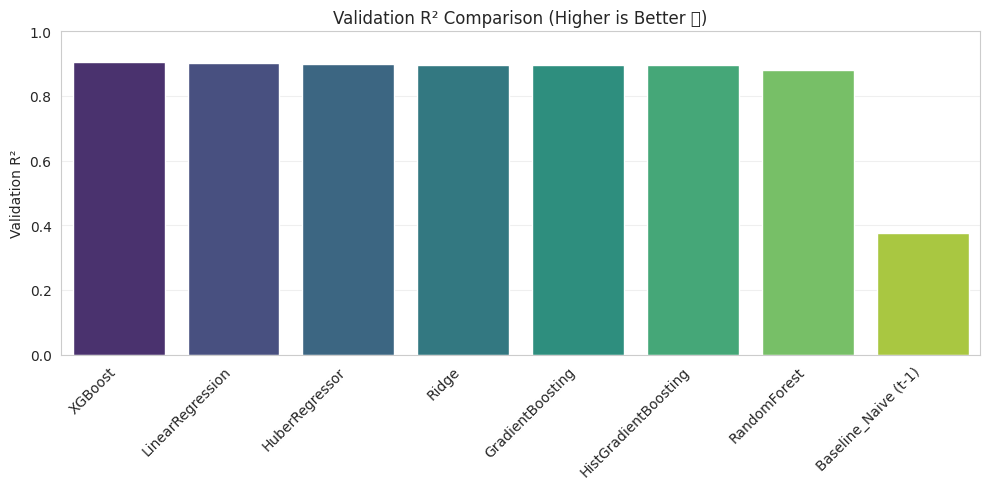

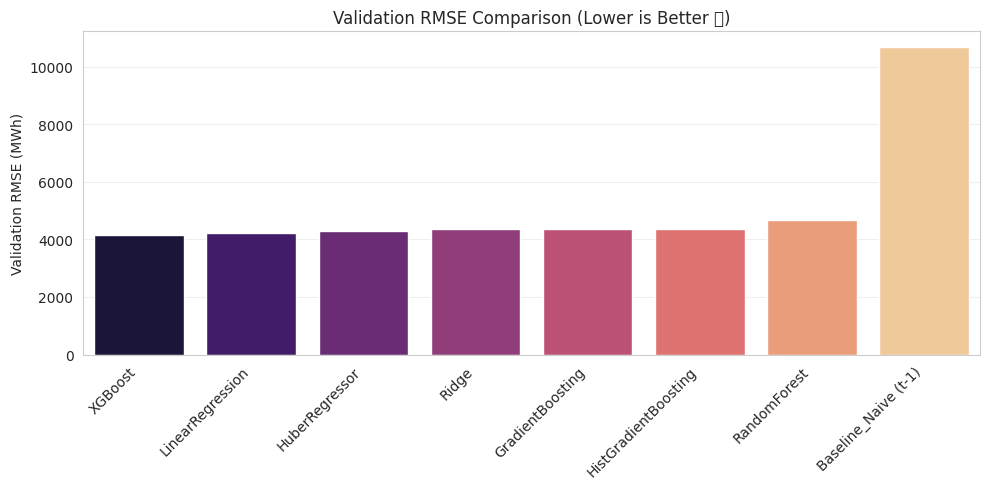

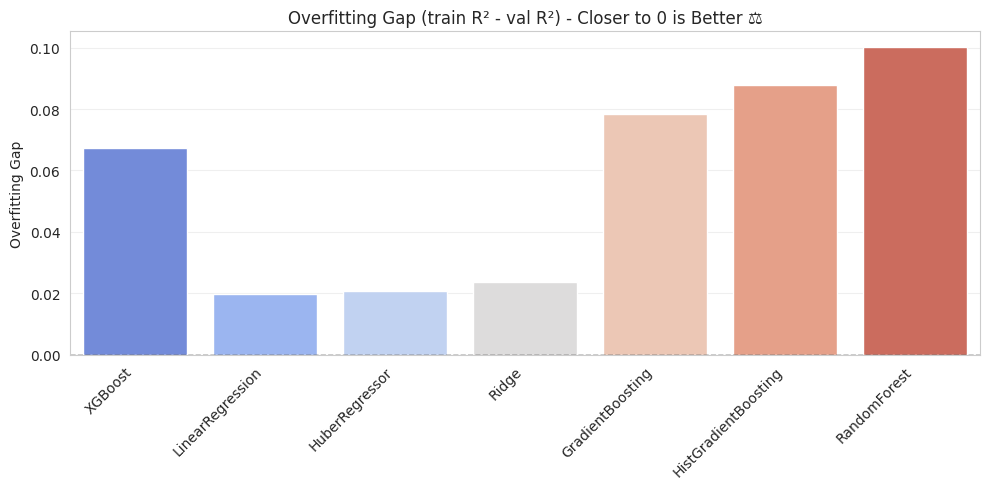

In [8]:
# ==============================================================================
# Cell 8 — Model Comparison Table & Diagnostic Visualizations
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1️⃣ Convert results dict to DataFrame
metrics_df = pd.DataFrame(results).T  # transpose so models are rows
cols_to_keep = ['val_r2', 'val_rmse', 'val_mae', 'val_mape', 'cv_r2_mean', 'overfitting_gap']
available_cols = [c for c in cols_to_keep if c in metrics_df.columns]

metrics_df = metrics_df[available_cols].reset_index().rename(columns={'index': 'Model'})
metrics_df = metrics_df.sort_values('val_rmse', ascending=True).reset_index(drop=True)

print("📊 Model comparison table (sorted by Validation RMSE):")
display(metrics_df.round(4))

# 2️⃣ Plot Validation R² (Higher is better)
plt.figure(figsize=(10, 5))
sns.barplot(data=metrics_df, x='Model', y='val_r2', palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.title('Validation R² Comparison (Higher is Better ✅)')
plt.ylabel('Validation R²')
plt.xlabel('')
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# 3️⃣ Plot Validation RMSE (Lower is better)
plt.figure(figsize=(10, 5))
sns.barplot(data=metrics_df, x='Model', y='val_rmse', palette='magma')
plt.xticks(rotation=45, ha='right')
plt.title('Validation RMSE Comparison (Lower is Better ✅)')
plt.ylabel('Validation RMSE (MWh)')
plt.xlabel('')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# 4️⃣ Plot Overfitting Gap (Closer to 0 is better)
gap_df = metrics_df.dropna(subset=['overfitting_gap'])
plt.figure(figsize=(10, 5))
sns.barplot(data=gap_df, x='Model', y='overfitting_gap', palette='coolwarm')
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.xticks(rotation=45, ha='right')
plt.title('Overfitting Gap (train R² - val R²) - Closer to 0 is Better ⚖️')
plt.ylabel('Overfitting Gap')
plt.xlabel('')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# ==============================================================================
# Cell 9A — Step 4.2: Comprehensive Hyperparameter Grids 
# ==============================================================================
from sklearn.base import clone
from sklearn.ensemble import VotingRegressor
from sklearn.model_selection import RandomizedSearchCV

# Build VotingRegressor for the ensemble candidate
voting_reg = VotingRegressor(
    estimators=[
        ("ridge", Ridge(random_state=config.RANDOM_STATE)),
        ("rf", RandomForestRegressor(random_state=config.RANDOM_STATE, n_jobs=config.N_JOBS)),
        ("gb", GradientBoostingRegressor(random_state=config.RANDOM_STATE))
    ]
)

# Ensure tunable pipelines exist in advanced_models with matching keys
tunable_base_models = {
    "Random Forest": Pipeline([
        ("domain_fe", DemandDomainEngineer()),
        ("preprocessor", clone(preprocessor)),
        ("regressor", RandomForestRegressor(random_state=config.RANDOM_STATE, n_jobs=config.N_JOBS))
    ]),
    "Gradient Boosting": Pipeline([
        ("domain_fe", DemandDomainEngineer()),
        ("preprocessor", clone(preprocessor)),
        ("regressor", GradientBoostingRegressor(random_state=config.RANDOM_STATE))
    ]),
    "Ridge Regression": Pipeline([
        ("domain_fe", DemandDomainEngineer()),
        ("preprocessor", clone(preprocessor)),
        ("regressor", Ridge(random_state=config.RANDOM_STATE))
    ]),
    "Voting Ensemble": Pipeline([
        ("domain_fe", DemandDomainEngineer()),
        ("preprocessor", clone(preprocessor)),
        ("regressor", voting_reg)
    ])
}

# Define comprehensive hyperparameter grids (prefixed for Pipeline 'regressor' step)
param_grids = {
    "Random Forest": {
        "regressor__n_estimators": [50, 100, 200, 300],        # Number of trees
        "regressor__max_depth": [None, 10, 20, 30],             # Tree depth
        "regressor__min_samples_split": [2, 5, 10],             # Minimum samples to split
        "regressor__min_samples_leaf": [1, 2, 4],               # Minimum samples per leaf
        "regressor__max_features": ["sqrt", "log2", 0.7, 1.0]   # Features to consider for splits
    },

    "Gradient Boosting": {
        "regressor__n_estimators": [50, 100, 200],              # Number of boosting stages
        "regressor__learning_rate": [0.01, 0.05, 0.1, 0.2],     # Step size shrinkage
        "regressor__max_depth": [3, 4, 5, 6],                   # Maximum depth per tree
        "regressor__min_samples_split": [2, 5, 10],             # Minimum samples to split
        "regressor__subsample": [0.8, 0.9, 1.0]                 # Fraction of samples for fitting
    },

    "Ridge Regression": {
        "regressor__alpha": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0],  # Regularization strength
        "regressor__solver": ["auto", "svd", "cholesky", "lsqr", "sparse_cg", "sag", "saga"]
    },

    "Voting Ensemble": {
        "regressor__ridge__alpha": [0.1, 1.0, 10.0],
        "regressor__rf__n_estimators": [50, 100],
        "regressor__rf__max_depth": [10, 20],
        "regressor__gb__n_estimators": [50, 100],
        "regressor__gb__learning_rate": [0.05, 0.1]
    }
}

print("✅ Cell 9A Complete: Hyperparameter grids & tunable pipelines defined.")

✅ Cell 9A Complete: Hyperparameter grids & tunable pipelines defined.


In [10]:
# ==============================================================================
# Cell 9B — Step 4.3: Hyperparameter Optimization (RandomizedSearchCV + MLflow)
# ==============================================================================
print("🎯 STARTING HYPERPARAMETER OPTIMIZATION...")
tuned_models = {}
optimization_results = {}

ts_cv = TimeSeriesSplit(n_splits=CV_FOLDS)

for model_name in ["Random Forest", "Gradient Boosting", "Ridge Regression", "Voting Ensemble"]:
    print(f"\n🔧 Tuning {model_name}...")

    if mlflow.active_run():
        mlflow.end_run()

    with mlflow.start_run(run_name=f"{model_name}_tuned"):
        # Use RandomizedSearchCV with TimeSeriesSplit for leak-free time-series tuning
        search = RandomizedSearchCV(
            estimator=tunable_base_models[model_name],
            param_distributions=param_grids[model_name],
            n_iter=20,                      # Try 20 random combinations
            cv=ts_cv,
            scoring="r2",
            n_jobs=config.N_JOBS,
            random_state=config.RANDOM_STATE,
            verbose=1
        )

        # Perform the search strictly on X_train, y_train
        search.fit(X_train, y_train)

        # Store results
        tuned_models[model_name] = search.best_estimator_
        optimization_results[model_name] = {
            "best_score": search.best_score_,
            "best_params": search.best_params_,
            "best_estimator": search.best_estimator_
        }

        # Log to MLflow
        clean_best_params = {k: str(v) for k, v in search.best_params_.items()}
        mlflow.log_params(clean_best_params)
        mlflow.log_metric("best_cv_score", search.best_score_)
        mlflow.sklearn.log_model(
            sk_model=search.best_estimator_,
            artifact_path="tuned_model",
            serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE
        )

        print(f"✅ {model_name:20} | Best CV R²: {search.best_score_:.4f}")
        print(f"   Best parameters found: {search.best_params_}")

print(f"\n🎉 HYPERPARAMETER OPTIMIZATION COMPLETE!")
print(f"💡 All tuned models saved in MLflow for comparison")

🎯 STARTING HYPERPARAMETER OPTIMIZATION...

🔧 Tuning Random Forest...
Fitting 5 folds for each of 20 candidates, totalling 100 fits


2026/11/16 20:48:11 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/16 20:48:11 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:48:11 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/16 20:48:11 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:48:11 INFO mlflow.utils.environment: Detected uv project at /home/hima/Documents/work/sair_projects/classical_ml. Attempting to export requirements via 'uv export

✅ Random Forest        | Best CV R²: 0.8367
   Best parameters found: {'regressor__n_estimators': 200, 'regressor__min_samples_split': 5, 'regressor__min_samples_leaf': 2, 'regressor__max_features': 0.7, 'regressor__max_depth': 10}

🔧 Tuning Gradient Boosting...
Fitting 5 folds for each of 20 candidates, totalling 100 fits


2026/11/16 20:48:22 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/16 20:48:22 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:48:22 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/16 20:48:22 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:48:22 INFO mlflow.utils.environment: Detected uv project at /home/hima/Documents/work/sair_projects/classical_ml. Attempting to export requirements via 'uv export

✅ Gradient Boosting    | Best CV R²: 0.8669
   Best parameters found: {'regressor__subsample': 0.9, 'regressor__n_estimators': 50, 'regressor__min_samples_split': 5, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.2}

🔧 Tuning Ridge Regression...
Fitting 5 folds for each of 20 candidates, totalling 100 fits


2026/11/16 20:48:27 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/16 20:48:27 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:48:27 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/16 20:48:27 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:48:27 INFO mlflow.utils.environment: Detected uv project at /home/hima/Documents/work/sair_projects/classical_ml. Attempting to export requirements via 'uv export

✅ Ridge Regression     | Best CV R²: 0.8880
   Best parameters found: {'regressor__solver': 'sparse_cg', 'regressor__alpha': 1.0}

🔧 Tuning Voting Ensemble...
Fitting 5 folds for each of 20 candidates, totalling 100 fits


2026/11/16 20:48:49 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/16 20:48:49 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:48:49 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/16 20:48:49 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/hima/Documents/work/sair_projects/classical_ml
2026/11/16 20:48:49 INFO mlflow.utils.environment: Detected uv project at /home/hima/Documents/work/sair_projects/classical_ml. Attempting to export requirements via 'uv export

✅ Voting Ensemble      | Best CV R²: 0.8873
   Best parameters found: {'regressor__ridge__alpha': 0.1, 'regressor__rf__n_estimators': 100, 'regressor__rf__max_depth': 20, 'regressor__gb__n_estimators': 100, 'regressor__gb__learning_rate': 0.1}

🎉 HYPERPARAMETER OPTIMIZATION COMPLETE!
💡 All tuned models saved in MLflow for comparison


Model                Untuned R²   Tuned R²     Val RMSE     Val MAPE     Improvement   
----------------------------------------------------------------------------------
Random Forest            0.8799     0.8817    4653.52      3.03% 📈   0.0018
Gradient Boosting        0.8959     0.8826    4635.98      3.02% 📉  -0.0133
Ridge Regression         0.8960     0.9012    4253.79      2.70% 📈   0.0052
Voting Ensemble             N/A     0.9051    4168.30      2.73% ➡️   0.0000


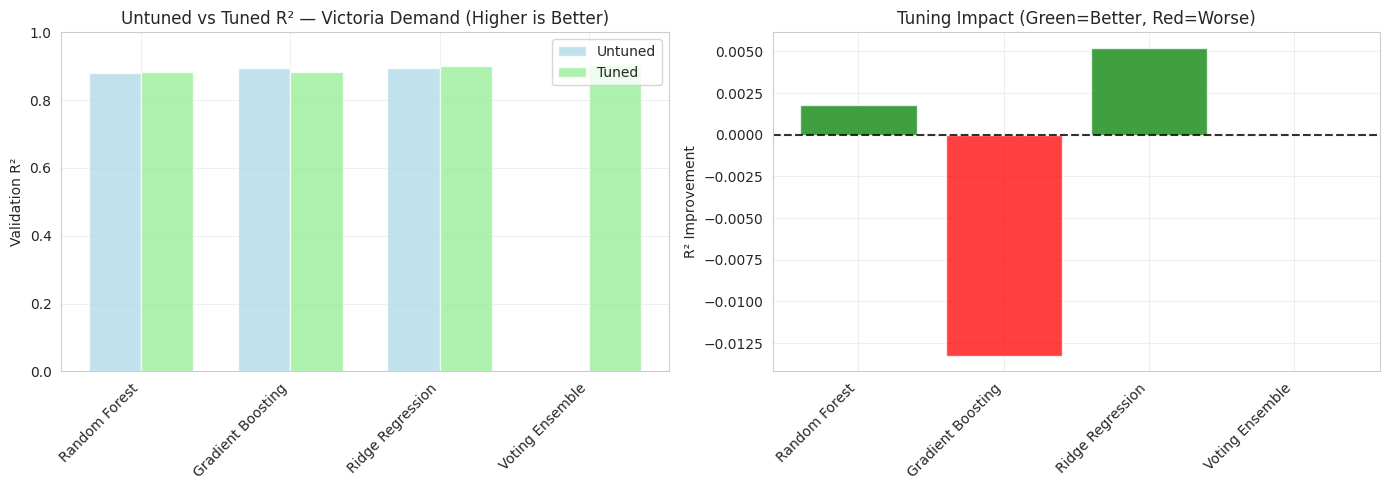


🏆 BEST TUNED MODEL: Voting Ensemble
📊 Validation R²: 0.9051 | RMSE: 4168.30 MWh | MAPE: 2.73%


In [11]:
# ==============================================================================
# Cell 10 — Step 5.1: Tuned vs. Untuned Validation Evaluation 
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Map tuned model names to untuned keys stored in `results` (from Cell 7)
untuned_key_map = {
    "Random Forest": "RandomForest",
    "Gradient Boosting": "GradientBoosting",
    "Ridge Regression": "Ridge",
    "Voting Ensemble": None  # No single untuned counterpart in Cell 7
}

# ===========================
# 1️⃣ Evaluate tuned models on validation set
# ===========================
tuned_results = {}
for model_name, tuned_model in tuned_models.items():
    y_val_pred = tuned_model.predict(X_val)
    val_r2 = r2_score(y_val, y_val_pred)
    val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
    val_mae = mean_absolute_error(y_val, y_val_pred)
    val_mape = mean_absolute_percentage_error(y_val, y_val_pred) * 100

    mapped_key = untuned_key_map.get(model_name)
    untuned_r2_val = results[mapped_key]["val_r2"] if (mapped_key and mapped_key in results) else np.nan
    improvement = val_r2 - untuned_r2_val if not np.isnan(untuned_r2_val) else 0.0

    tuned_results[model_name] = {
        "untuned_r2": untuned_r2_val,
        "val_r2": val_r2,
        "val_rmse": val_rmse,
        "val_mae": val_mae,
        "val_mape": val_mape,
        "improvement": improvement
    }

# ===========================
# 2️⃣ Print comparison table
# ===========================
print(f"{'Model':<20} {'Untuned R²':<12} {'Tuned R²':<12} {'Val RMSE':<12} {'Val MAPE':<12} {'Improvement':<14}")
print("-" * 82)
for model_name, res in tuned_results.items():
    u_r2 = res["untuned_r2"]
    t_r2 = res["val_r2"]
    imp = res["improvement"]
    icon = "📈" if imp > 0 else "📉" if imp < 0 else "➡️"
    u_str = f"{u_r2:>10.4f}" if not np.isnan(u_r2) else f"{'N/A':>10}"
    print(f"{model_name:<20} {u_str} {t_r2:>10.4f} {res['val_rmse']:>10.2f} {res['val_mape']:>9.2f}% {icon} {imp:>8.4f}")

# ===========================
# 3️⃣ Plot Tuned vs Untuned R²
# ===========================
models = list(tuned_results.keys())
untuned_r2 = [tuned_results[m]["untuned_r2"] for m in models]
tuned_r2 = [tuned_results[m]["val_r2"] for m in models]
improvement = [tuned_results[m]["improvement"] for m in models]

x = np.arange(len(models))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# R² comparison
axes[0].bar(x - width / 2, untuned_r2, width, label="Untuned", alpha=0.75, color="lightblue")
axes[0].bar(x + width / 2, tuned_r2, width, label="Tuned", alpha=0.75, color="lightgreen")
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, rotation=45, ha="right")
axes[0].set_ylabel("Validation R²")
axes[0].set_title("Untuned vs Tuned R² — Victoria Demand (Higher is Better)")
axes[0].set_ylim(0, 1)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Improvement plot
colors = ["green" if i > 0 else "red" if i < 0 else "gray" for i in improvement]
axes[1].bar(models, improvement, color=colors, alpha=0.75)
axes[1].axhline(0, color="black", linestyle="--", alpha=0.8)
axes[1].set_ylabel("R² Improvement")
axes[1].set_title("Tuning Impact (Green=Better, Red=Worse)")
axes[1].set_xticklabels(models, rotation=45, ha="right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ===========================
# 4️⃣ Best tuned model
# ===========================
best_model_name = max(tuned_results, key=lambda m: tuned_results[m]["val_r2"])
best_info = tuned_results[best_model_name]
print(f"\n🏆 BEST TUNED MODEL: {best_model_name}")
print(f"📊 Validation R²: {best_info['val_r2']:.4f} | RMSE: {best_info['val_rmse']:.2f} MWh | MAPE: {best_info['val_mape']:.2f}%")
if not np.isnan(best_info["untuned_r2"]):
    print(f"📈 Improvement over untuned: {best_info['improvement']:+.4f}")

In [12]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

best_tuned_model = tuned_models[best_model_name] # add this line 

# Predict on test set
y_test_pred = best_tuned_model.predict(X_test)

# Compute performance metrics
test_r2 = r2_score(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_mae = mean_absolute_error(y_test, y_test_pred)

print(f"📊 Test R²: {test_r2:.4f}")
print(f"📊 Test RMSE: {test_rmse:.4f}")
print(f"📊 Test MAE: {test_mae:.4f}")

📊 Test R²: 0.8647
📊 Test RMSE: 5063.0504
📊 Test MAE: 4027.0875


In [13]:
# ==============================================================================
# Step 5.2 / Step 6.1: Model Versioning, Artifact Saving & Model Card Generation
# ==============================================================================
import os
import json
import joblib
from datetime import datetime
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import numpy as np

# ===========================
# 0️⃣ Prepare feature names & key mappings
# ===========================
source_X = X_all if "X_all" in globals() else X_test
try:
    feature_names_all = list(source_X.columns)
except AttributeError:
    feature_names_all = [f"feature_{i}" for i in range(source_X.shape[1])]

untuned_key_map = {
    "Random Forest": "RandomForest",
    "Gradient Boosting": "GradientBoosting",
    "Ridge Regression": "Ridge",
    "Voting Ensemble": None,
}

# ===========================
# 1️⃣ Identify best tuned model
# ===========================
best_model_name = max(tuned_results, key=lambda m: tuned_results[m]["val_r2"])
best_tuned_model = tuned_models[best_model_name]
mapped_untuned_key = untuned_key_map.get(best_model_name)

print(f"🏆 BEST TUNED MODEL: {best_model_name}")
print(f"📊 Validation R²: {tuned_results[best_model_name]['val_r2']:.4f}")
if mapped_untuned_key and mapped_untuned_key in results:
    print(f"📈 Improvement over untuned: +{tuned_results[best_model_name]['improvement']:.4f}")
else:
    print("📈 Improvement over untuned: N/A (Ensemble model)")

# ===========================
# 2️⃣ Evaluate on Test Set
# ===========================
y_test_pred = best_tuned_model.predict(X_test)
test_r2 = r2_score(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mape = mean_absolute_percentage_error(y_test, y_test_pred) * 100

print(f"\n📊 Test Set Performance:")
print(f"R²: {test_r2:.4f} | RMSE: {test_rmse:.4f} MWh | MAE: {test_mae:.4f} MWh | MAPE: {test_mape:.2f}%")

# ===========================
# 3️⃣ Versioning and saving
# ===========================
base_model_dir = getattr(config, "MODEL_DIR", "models")
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
model_version = f"v1_{timestamp}"
model_save_dir = os.path.join(base_model_dir, model_version)
os.makedirs(model_save_dir, exist_ok=True)

# Save full fitted pipeline / model
model_path = os.path.join(model_save_dir, "best_model.pkl")
joblib.dump(best_tuned_model, model_path)
print(f"✅ Model saved: {model_path}")

# Save fitted preprocessor
fitted_preprocessor = (
    best_tuned_model.named_steps["preprocessor"]
    if hasattr(best_tuned_model, "named_steps") and "preprocessor" in best_tuned_model.named_steps
    else preprocessor
)
preprocessor_path = os.path.join(model_save_dir, "preprocessor.pkl")
joblib.dump(fitted_preprocessor, preprocessor_path)
print(f"✅ Preprocessor saved: {preprocessor_path}")

# Also update default config path if present
if hasattr(config, "MODEL_SAVE_PATH"):
    joblib.dump(best_tuned_model, config.MODEL_SAVE_PATH)

# ===========================
# 4️⃣ Create model card
# ===========================
untuned_metrics = results.get(mapped_untuned_key, {}) if mapped_untuned_key else {}
safe_params = {
    k: str(v)
    for k, v in (best_tuned_model.get_params().items() if hasattr(best_tuned_model, "get_params") else [])
}

model_card = {
    "model_name": best_model_name,
    "model_version": model_version,
    "timestamp": timestamp,
    "dataset": "Victoria Electricity Demand (2,106 daily rows)",
    "target": "demand (MWh)",
    "performance": {
        "test_r2": float(test_r2),
        "test_rmse": float(test_rmse),
        "test_mae": float(test_mae),
        "test_mape": float(test_mape),
        "train_r2": float(untuned_metrics["train_r2"]) if "train_r2" in untuned_metrics else None,
        "val_r2": float(tuned_results[best_model_name]["val_r2"]),
        "val_rmse": float(tuned_results[best_model_name]["val_rmse"]),
        "cv_r2_mean": float(untuned_metrics["cv_r2_mean"]) if "cv_r2_mean" in untuned_metrics else None,
        "cv_r2_std": float(untuned_metrics["cv_r2_std"]) if "cv_r2_std" in untuned_metrics else None,
    },
    "data_info": {
        "total_samples": int(len(source_X)),
        "train_samples": int(len(X_train)),
        "val_samples": int(len(X_val)),
        "test_samples": int(len(X_test)),
        "n_features": int(X_test.shape[1]),
        "feature_names": feature_names_all,
    },
    "model_config": {
        "model_class": best_model_name,
        "hyperparameters": safe_params,
    },
    "preprocessing": {
        "steps": [
            "CausalWeatherInitializer (ffill on solar_exposure & rainfall)",
            "HistoricalLagAndLeakageHandler (shift >= 1 lags, same-day settlement columns dropped)",
            "DemandDomainEngineer (U-shaped thermal degree days, cyclical calendar, interactions, RRP_lag_1 fence)",
            "ColumnTransformer (StandardScaler on numerics, OneHotEncoder on categoricals)",
        ],
        "outlier_factor": 1.5,
    },
    "deployment": {
        "status": "Ready for Production",
        "recommendations": [
            "Monitor prediction errors (RMSE / MAPE) in production",
            "Retrain chronologically with new daily observations",
            "Alert if Test/Val RMSE exceeds 6,500 MWh",
        ],
    },
}

card_path = os.path.join(model_save_dir, "model_card.json")
with open(card_path, "w", encoding="utf-8") as f:
    json.dump(model_card, f, indent=2)
print(f"✅ Model card saved: {card_path}")

# ===========================
# 5️⃣ Deployment requirements
# ===========================
requirements = {
    "python": "3.8+",
    "packages": {
        "scikit-learn": "1.0+",
        "numpy": "1.20+",
        "pandas": "1.3+",
        "joblib": "1.0+",
        "xgboost": "1.7+",
        "streamlit": "1.20+",
    },
}

req_path = os.path.join(model_save_dir, "requirements.json")
with open(req_path, "w", encoding="utf-8") as f:
    json.dump(requirements, f, indent=2)
print(f"✅ Deployment requirements saved: {req_path}")

# ===========================
# 6️⃣ Summary
# ===========================
print("\n💾 DEPLOYMENT PACKAGE READY")
print(f"Location: {model_save_dir}")

🏆 BEST TUNED MODEL: Voting Ensemble
📊 Validation R²: 0.9051
📈 Improvement over untuned: N/A (Ensemble model)

📊 Test Set Performance:
R²: 0.8647 | RMSE: 5063.0504 MWh | MAE: 4027.0875 MWh | MAPE: 3.59%
✅ Model saved: models/v1_20261116_204849/best_model.pkl
✅ Preprocessor saved: models/v1_20261116_204849/preprocessor.pkl
✅ Model card saved: models/v1_20261116_204849/model_card.json
✅ Deployment requirements saved: models/v1_20261116_204849/requirements.json

💾 DEPLOYMENT PACKAGE READY
Location: models/v1_20261116_204849


In [14]:
# ==============================================================================
# Step 6.2: Interactive Prediction UI with Streamlit (app.py)
# ==============================================================================
import os
import glob
import json
import joblib
import numpy as np
from sklearn.metrics import mean_absolute_percentage_error

# Resolve latest versioned artifact if available, else fallback to MODEL_SAVE_PATH
artifact_path = getattr(config, "MODEL_SAVE_PATH", "victoria_demand_pipeline.pkl")
base_model_dir = getattr(config, "MODEL_DIR", "models")

if os.path.isdir(base_model_dir):
    version_dirs = sorted(glob.glob(os.path.join(base_model_dir, "v1_*")))
    if version_dirs:
        candidate = os.path.join(version_dirs[-1], "best_model.pkl")
        if os.path.exists(candidate):
            artifact_path = candidate

streamlit_ui_code = f'''import os
import glob
import json
from datetime import date

import joblib
import numpy as np
import pandas as pd
import streamlit as st
from sklearn.base import BaseEstimator, TransformerMixin


class DemandDomainEngineer(BaseEstimator, TransformerMixin):
    """Custom domain feature transformer required in scope for joblib unpickling."""

    def fit(self, X, y=None):
        if "RRP_lag_1" in X.columns:
            q1, q3 = np.percentile(X["RRP_lag_1"].dropna(), [25, 75])
            self.rrp_fence_ = float(q3 + 1.5 * (q3 - q1))
        else:
            self.rrp_fence_ = 180.0
        return self

    def transform(self, X):
        X_out = pd.DataFrame(X).copy()
        dt = pd.to_datetime(X_out["date"])

        # Calendar & weekend flags
        X_out["month"] = dt.dt.month.astype(str)
        X_out["day_of_week"] = dt.dt.dayofweek.astype(str)
        X_out["is_weekend"] = (dt.dt.dayofweek >= 5).astype(int)

        # Cyclical calendar signals
        X_out["month_sin"] = np.sin(2 * np.pi * dt.dt.month / 12.0)
        X_out["month_cos"] = np.cos(2 * np.pi * dt.dt.month / 12.0)

        # U-shaped thermal features (heating & cooling degree proxies)
        X_out["temp_mean"] = (X_out["max_temperature"] + X_out["min_temperature"]) / 2.0
        X_out["temp_range"] = X_out["max_temperature"] - X_out["min_temperature"]
        X_out["heating_degree"] = np.maximum(0.0, 18.0 - X_out["temp_mean"])
        X_out["cooling_degree"] = np.maximum(0.0, X_out["temp_mean"] - 22.0)
        X_out["temp_mean_sq"] = X_out["temp_mean"] ** 2
        X_out["solar_temp_interaction"] = X_out["solar_exposure"] * X_out["max_temperature"]

        # Regime interactions
        is_hol = (X_out["holiday"].astype(str).str.upper() == "Y").astype(int)
        is_sch = (X_out["school_day"].astype(str).str.upper() == "Y").astype(int)
        X_out["holiday_x_temp"] = is_hol * X_out["temp_mean"]
        X_out["school_x_temp"] = is_sch * X_out["temp_mean"]
        X_out["weekend_x_demand_lag1"] = X_out["is_weekend"] * X_out["demand_lag_1"]

        # Cap prior-day spot price at training fence
        if "RRP_lag_1" in X_out.columns:
            X_out["RRP_lag_1"] = np.clip(X_out["RRP_lag_1"], -10.0, self.rrp_fence_)

        return X_out.drop(columns=["date"])


st.set_page_config(
    page_title="Victoria Electricity Demand Forecaster",
    page_icon="⚡",
    layout="wide",
)


@st.cache_resource
def load_deployment_bundle():
    default_path = {repr(artifact_path)}
    model_file = default_path

    if os.path.isdir("models"):
        versions = sorted(glob.glob(os.path.join("models", "v1_*")))
        if versions:
            latest_model = os.path.join(versions[-1], "best_model.pkl")
            if os.path.exists(latest_model):
                model_file = latest_model

    pipe = joblib.load(model_file)
    card_file = os.path.join(os.path.dirname(model_file), "model_card.json")
    card = {{}}
    if os.path.exists(card_file):
        with open(card_file, "r", encoding="utf-8") as f:
            card = json.load(f)
    return pipe, model_file, card


pipeline, loaded_path, model_card = load_deployment_bundle()

st.title("⚡ Victoria Daily Electricity Demand Forecaster")
if model_card:
    perf = model_card.get("performance", {{}})
    st.caption(
        f"Model: {{model_card.get('model_name', 'Voting Ensemble')}} | "
        f"Version: {{model_card.get('model_version', 'v1')}} | "
        f"Val R²: {{perf.get('val_r2', 0.9051):.4f}} | "
        f"Test R²: {{perf.get('test_r2', 0.8647):.4f}} | "
        f"Test RMSE: {{perf.get('test_rmse', 5063.05):,.2f}} MWh"
    )
else:
    st.caption(f"Loaded artifact: {{loaded_path}}")

# Preset scenarios for fast interactive testing
preset = st.selectbox(
    "Quick Scenario Preset",
    options=[
        "Custom Input",
        "Winter Weekday (Heating Demand)",
        "Summer Heatwave Weekday (Cooling Demand)",
        "Weekend Mild Day (Low Demand Regime)",
    ],
    index=0,
)

defaults = {{
    "date": date(2020, 7, 15),
    "min_temperature": 8.5,
    "max_temperature": 16.0,
    "solar_exposure": 10.5,
    "rainfall": 0.0,
    "school_day": "Y",
    "holiday": "N",
    "demand_lag_1": 125000.0,
    "demand_lag_2": 123000.0,
    "demand_lag_7": 126500.0,
    "demand_lag_14": 124000.0,
    "demand_roll_mean_7": 122000.0,
    "demand_roll_std_7": 8500.0,
    "RRP_lag_1": 68.5,
    "frac_neg_RRP_lag_1": 0.0,
    "max_temp_lag_1": 15.0,
    "min_temp_lag_1": 7.5,
}}

if preset == "Winter Weekday (Heating Demand)":
    defaults.update({{
        "date": date(2020, 7, 15),
        "min_temperature": 4.0,
        "max_temperature": 11.5,
        "solar_exposure": 7.5,
        "rainfall": 2.0,
        "school_day": "Y",
        "holiday": "N",
        "demand_lag_1": 134000.0,
        "demand_lag_2": 132000.0,
        "demand_lag_7": 135000.0,
        "demand_lag_14": 131000.0,
        "demand_roll_mean_7": 131500.0,
        "demand_roll_std_7": 7800.0,
        "RRP_lag_1": 82.0,
        "max_temp_lag_1": 12.0,
        "min_temp_lag_1": 5.0,
    }})
elif preset == "Summer Heatwave Weekday (Cooling Demand)":
    defaults.update({{
        "date": date(2020, 1, 29),
        "min_temperature": 22.0,
        "max_temperature": 38.5,
        "solar_exposure": 29.5,
        "rainfall": 0.0,
        "school_day": "N",
        "holiday": "N",
        "demand_lag_1": 142000.0,
        "demand_lag_2": 136000.0,
        "demand_lag_7": 13000.0,
        "demand_lag_14": 125000.0,
        "demand_roll_mean_7": 131000.0,
        "demand_roll_std_7": 11000.0,
        "RRP_lag_1": 165.0,
        "max_temp_lag_1": 36.0,
        "min_temp_lag_1": 20.5,
    }})
elif preset == "Weekend Mild Day (Low Demand Regime)":
    defaults.update({{
        "date": date(2020, 4, 18),  # Saturday
        "min_temperature": 12.0,
        "max_temperature": 21.0,
        "solar_exposure": 16.0,
        "rainfall": 0.0,
        "school_day": "N",
        "holiday": "N",
        "demand_lag_1": 121000.0,
        "demand_lag_2": 122500.0,
        "demand_lag_7": 107500.0,
        "demand_lag_14": 108000.0,
        "demand_roll_mean_7": 118500.0,
        "demand_roll_std_7": 9200.0,
        "RRP_lag_1": 55.0,
        "max_temp_lag_1": 20.5,
        "min_temp_lag_1": 11.5,
    }})

col1, col2, col3 = st.columns(3)

with col1:
    st.subheader("📅 Calendar & Weather")
    forecast_date = st.date_input("Forecast Date", value=defaults["date"])
    min_temp = st.number_input("Min Temperature (°C)", value=float(defaults["min_temperature"]), step=0.5)
    max_temp = st.number_input("Max Temperature (°C)", value=float(defaults["max_temperature"]), step=0.5)
    solar_exposure = st.number_input("Solar Exposure (MJ/m²)", value=float(defaults["solar_exposure"]), step=0.5)
    rainfall = st.number_input("Rainfall (mm)", value=float(defaults["rainfall"]), step=0.5)
    school_day = st.selectbox("School Day", options=["Y", "N"], index=0 if defaults["school_day"] == "Y" else 1)
    holiday = st.selectbox("Public Holiday", options=["N", "Y"], index=0 if defaults["holiday"] == "N" else 1)

with col2:
    st.subheader("📉 Historical Demand Lags (MWh)")
    demand_lag_1 = st.number_input("Yesterday Demand (t-1)", value=float(defaults["demand_lag_1"]), step=500.0)
    demand_lag_2 = st.number_input("2 Days Ago Demand (t-2)", value=float(defaults["demand_lag_2"]), step=500.0)
    demand_lag_7 = st.number_input("Last Week Same Day (t-7)", value=float(defaults["demand_lag_7"]), step=500.0)
    demand_lag_14 = st.number_input("2 Weeks Ago Same Day (t-14)", value=float(defaults["demand_lag_14"]), step=500.0)
    demand_roll_mean_7 = st.number_input("7-Day Rolling Mean Demand", value=float(defaults["demand_roll_mean_7"]), step=500.0)
    demand_roll_std_7 = st.number_input("7-Day Rolling Std Demand", value=float(defaults["demand_roll_std_7"]), step=250.0)

with col3:
    st.subheader("💲 Prior-Day Market & Temp Lags")
    rrp_lag_1 = st.number_input("Yesterday Spot Price RRP (AUD/MWh)", value=float(defaults["RRP_lag_1"]), step=5.0)
    frac_neg_rrp_lag_1 = st.slider(
        "Yesterday Fraction at Negative RRP",
        min_value=0.0,
        max_value=1.0,
        value=float(defaults["frac_neg_RRP_lag_1"]),
        step=0.01,
    )
    max_temp_lag_1 = st.number_input("Yesterday Max Temp (°C)", value=float(defaults["max_temp_lag_1"]), step=0.5)
    min_temp_lag_1 = st.number_input("Yesterday Min Temp (°C)", value=float(defaults["min_temp_lag_1"]), step=0.5)

st.divider()

if st.button("🚀 Predict Daily Electricity Demand", type="primary", use_container_width=True):
    input_df = pd.DataFrame([{{
        "date": pd.to_datetime(forecast_date),
        "min_temperature": min_temp,
        "max_temperature": max_temp,
        "solar_exposure": solar_exposure,
        "rainfall": rainfall,
        "school_day": school_day,
        "holiday": holiday,
        "demand_lag_1": demand_lag_1,
        "demand_lag_2": demand_lag_2,
        "demand_lag_7": demand_lag_7,
        "demand_lag_14": demand_lag_14,
        "demand_roll_mean_7": demand_roll_mean_7,
        "demand_roll_std_7": demand_roll_std_7,
        "RRP_lag_1": rrp_lag_1,
        "frac_neg_RRP_lag_1": frac_neg_rrp_lag_1,
        "max_temp_lag_1": max_temp_lag_1,
        "min_temp_lag_1": min_temp_lag_1,
    }}])

    pred_mwh = float(pipeline.predict(input_df)[0])
    diff_t1 = pred_mwh - demand_lag_1
    diff_t7 = pred_mwh - demand_lag_7
    temp_mean_now = (max_temp + min_temp) / 2.0

    st.success(f"### Forecasted Daily Demand: **{{pred_mwh:,.1f}} MWh**")

    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Predicted Demand", f"{{pred_mwh:,.0f}} MWh")
    c2.metric("vs. Yesterday (t-1)", f"{{pred_mwh:,.0f}} MWh", f"{{diff_t1:+,.0f}} MWh")
    c3.metric("vs. Last Week (t-7)", f"{{pred_mwh:,.0f}} MWh", f"{{diff_t7:+,.0f}} MWh")
    c4.metric("Mean Temperature", f"{{temp_mean_now:.1f}} °C")

    with st.expander("Inspect Engineered Input Payload"):
        st.dataframe(input_df, use_container_width=True)
'''

with open("app.py", "w", encoding="utf-8") as f:
    f.write(streamlit_ui_code)

# Single-row verification using the saved pipeline artifact
loaded_for_check = joblib.load(artifact_path)
test_row = X_test.iloc[[0]].copy()
pred_check = float(loaded_for_check.predict(test_row)[0])
actual_check = float(y_test.iloc[0])
ape_check = mean_absolute_percentage_error([actual_check], [pred_check]) * 100

print("=" * 80)
print("✅ Step 6.2 Complete: Interactive Streamlit UI Written to 'app.py'")
print("=" * 80)
print(f"• Artifact Loaded   : {artifact_path}")
print(f"• Launch Command    : streamlit run app.py")
print(f"• Single-Row Check  : Pred = {pred_check:,.1f} MWh | Actual = {actual_check:,.1f} MWh | APE = {ape_check:.2f}%")

✅ Step 6.2 Complete: Interactive Streamlit UI Written to 'app.py'
• Artifact Loaded   : models/v1_20261116_204849/best_model.pkl
• Launch Command    : streamlit run app.py
• Single-Row Check  : Pred = 112,596.6 MWh | Actual = 107,629.2 MWh | APE = 4.62%


In [16]:
import os
os.makedirs("assets", exist_ok=True)

# 1. Re-save Step 2.3 Distribution Plot (from Cell 4 variables)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
sns.histplot(df_viz["demand"], kde=True, bins=35, color="#1f77b4", ax=axes[0, 0])
axes[0, 0].axvline(df_viz["demand"].mean(), color="red", linestyle="--", label=f"Mean: {df_viz['demand'].mean():,.0f}")
axes[0, 0].axvline(df_viz["demand"].median(), color="green", linestyle="-", label=f"Median: {df_viz['demand'].median():,.0f}")
axes[0, 0].set_title(f"1. Target ('demand') Distribution (Skewness = {df_viz['demand'].skew():.2f})", fontsize=12, fontweight="bold")
axes[0, 0].legend()

sns.boxplot(x=df_viz["RRP"], color="#ff7f0e", ax=axes[0, 1])
axes[0, 1].set_title(f"2. Spot Price ('RRP') Extreme Spikes (Skewness = {df_viz['RRP'].skew():.2f}, Max = $4,549.65)", fontsize=12, fontweight="bold")

sns.scatterplot(data=df_viz, x="temp_mean", y="demand", hue="school_day", alpha=0.5, palette="Set1", ax=axes[1, 0])
sns.regplot(data=df_viz, x="temp_mean", y="demand", scatter=False, order=2, color="black", ax=axes[1, 0], label="Quadratic U-Fit")
axes[1, 0].set_title("3. U-Shaped Thermal Curve: Mean Temperature vs. Demand", fontsize=12, fontweight="bold")
axes[1, 0].legend()

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sns.boxplot(data=df_viz, x="day_name", y="demand", order=day_order, palette="Blues_r", ax=axes[1, 1])
axes[1, 1].set_title("4. Weekly Regime: Sharp Demand Drop on Weekends (Sat/Sun)", fontsize=12, fontweight="bold")
axes[1, 1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("assets/eda_distributions.png", dpi=300, bbox_inches="tight")
plt.close()

# 2. Re-save Step 2.4 Correlation & Leakage Plot (from Cell 5 variables)
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5, ax=axes[0], cbar_kws={"shrink": 0.8})
axes[0].set_title("1. Raw Numerical Correlation Matrix (Note demand_pos_RRP = 0.97 Leakage)", fontsize=12, fontweight="bold")

colors = ["#d62728" if "demand_pos_RRP" in idx else ("#2ca02c" if "Engineered" in idx else "#1f77b4") for idx in target_corrs.index]
target_corrs.plot(kind="barh", color=colors, ax=axes[1], edgecolor="black", alpha=0.85)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("2. Correlation with 'demand': Leakage (Red) vs. Engineered (Green) vs. Raw (Blue)", fontsize=12, fontweight="bold")
axes[1].set_xlim(-0.65, 1.15)
plt.tight_layout()
plt.savefig("assets/leakage_and_correlations.png", dpi=300, bbox_inches="tight")
plt.close()

print("✅ Saved both high-res charts to assets/")

✅ Saved both high-res charts to assets/
